1- In machine learning, clustering is the unsupervised learning technique that groups the data based on similarity between the set of data. 

2- There are different-different types of clustering algorithms in machine learning. 

    a- Connectivity-based clustering: This type of clustering algorithm builds the cluster based on the connectivity between the data points. 

    Example: Hierarchical clustering

    b- Centroid-based clustering: This type of clustering algorithm forms around the centroids of the data points. 

    Example: K-Means clustering, K-Mode clustering

    c- Distribution-based clustering: This type of clustering algorithm is modeled using statistical distributions. It assumes that the data points in a cluster are generated from a particular probability distribution, and the algorithm aims to estimate the parameters of the distribution to group similar data points into clusters 

    Example: Gaussian Mixture Models (GMM)

    d- Density-based clustering: This type of clustering algorithm groups together data points that are in high-density concentrations and separates points in low-concentrations regions. The basic idea is that it identifies regions in the data space that have a high density of data points and groups those points together into clusters. 

    Example: DBSCAN(Density-Based Spatial Clustering of Applications with Noise)

In [1]:
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("income.csv")
df.head()

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


Text(0, 0.5, 'Income($)')

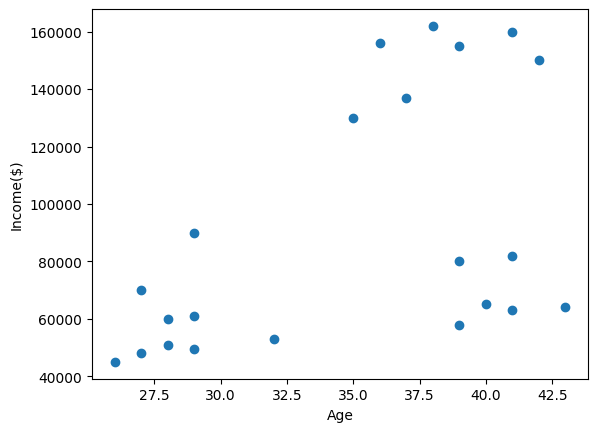

In [3]:
plt.scatter(df.Age,df['Income($)'])
plt.xlabel('Age')
plt.ylabel('Income($)')

In [4]:
km = KMeans(n_clusters=3)
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([1, 1, 1, 1, 2, 2, 2, 2, 2, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [5]:
df['cluster']=y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,27,70000,1
1,Michael,29,90000,1
2,Mohan,29,61000,1
3,Ismail,28,60000,1
4,Kory,42,150000,2


In [6]:
km.cluster_centers_

array([[3.60000000e+01, 1.33500000e+05],
       [3.32000000e+01, 6.26333333e+04],
       [3.92000000e+01, 1.56600000e+05]])

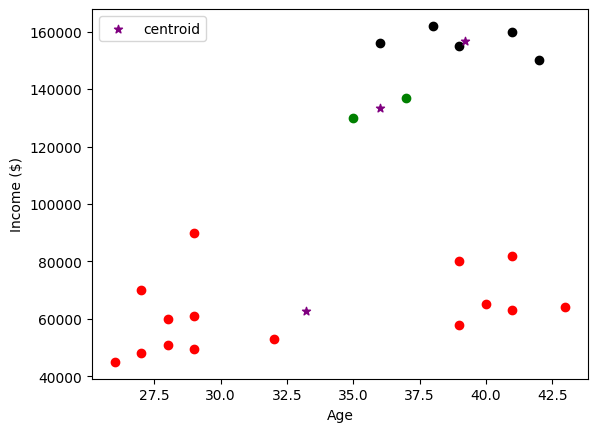

In [7]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.legend()

<h4 style='color:purple'>Preprocessing using min max scaler</h4>

In [8]:
scaler = MinMaxScaler()

scaler.fit(df[['Income($)']])
df['Income($)'] = scaler.transform(df[['Income($)']])

scaler.fit(df[['Age']])
df['Age'] = scaler.transform(df[['Age']])

In [9]:
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,2


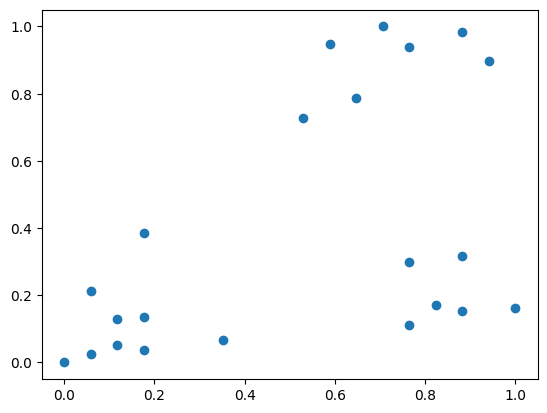

In [10]:
plt.scatter(df.Age,df['Income($)'])

In [11]:
km = KMeans(n_clusters=3)
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1])

In [12]:
df['cluster']=y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,0
1,Michael,0.176471,0.384615,0
2,Mohan,0.176471,0.136752,0
3,Ismail,0.117647,0.128205,0
4,Kory,0.941176,0.897436,2


In [13]:
km.cluster_centers_

array([[0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ],
       [0.72268908, 0.8974359 ]])

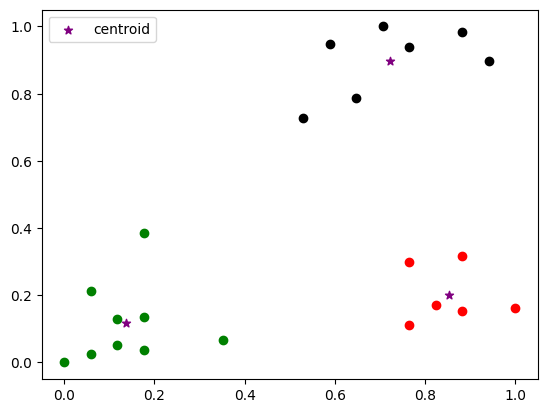

In [14]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.legend()

<h4 style='color:purple'>Elbow Plot</h4>

In [15]:
sse = []
k_rng = range(1,10)
for k in k_rng:
    km = KMeans(n_clusters=k)
    km.fit(df[['Age','Income($)']])
    sse.append(km.inertia_)

c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarn

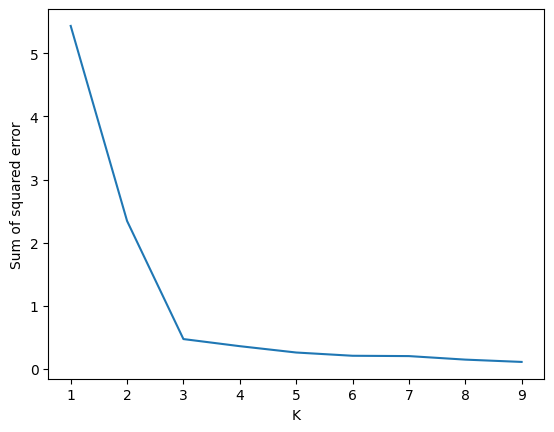

In [16]:
plt.xlabel('K')
plt.ylabel('Sum of squared error')
plt.plot(k_rng,sse)

1. Use iris flower dataset from sklearn library and try to form clusters of flowers using petal width and length features. Drop other two features for simplicity.
2. Figure out if any preprocessing such as scaling would help here
3. Draw elbow plot and from that figure out optimal value of k

In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

In [18]:
X, y = load_iris(return_X_y=True)

Elbow Method 

1- Finding the ideal number of groups to divide the data into is a basic stage in any unsupervised algorithm. 

2- One of the most common techniques for figuring out this ideal value of k is the elbow approach.

In [19]:
#Find optimum number of cluster
sse = [] #SUM OF SQUARED ERROR
for k in range(1,11):
    km = KMeans(n_clusters=k, random_state=2)
    km.fit(X)
    sse.append(km.inertia_)

c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarn

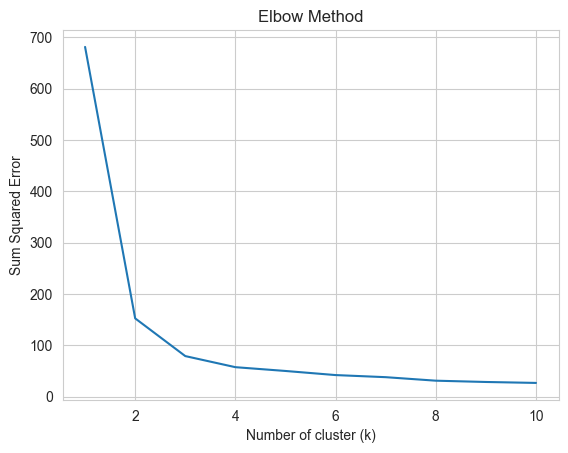

In [20]:
sns.set_style("whitegrid")
g=sns.lineplot(x=range(1,11), y=sse)
 
g.set(xlabel ="Number of cluster (k)", 
      ylabel = "Sum Squared Error", 
      title ='Elbow Method')
 
plt.show()

From the above graph, we can observe that at k=2 and k=3 elbow-like situation. So, we are considering K=3

In [21]:
kmeans = KMeans(n_clusters = 3, random_state = 2)
kmeans.fit(X)

c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=3, random_state=2)

In [22]:
kmeans.cluster_centers_

array([[5.9016129 , 2.7483871 , 4.39354839, 1.43387097],
       [5.006     , 3.428     , 1.462     , 0.246     ],
       [6.85      , 3.07368421, 5.74210526, 2.07105263]])

In [23]:
pred = kmeans.fit_predict(X)
pred

c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 0, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0])

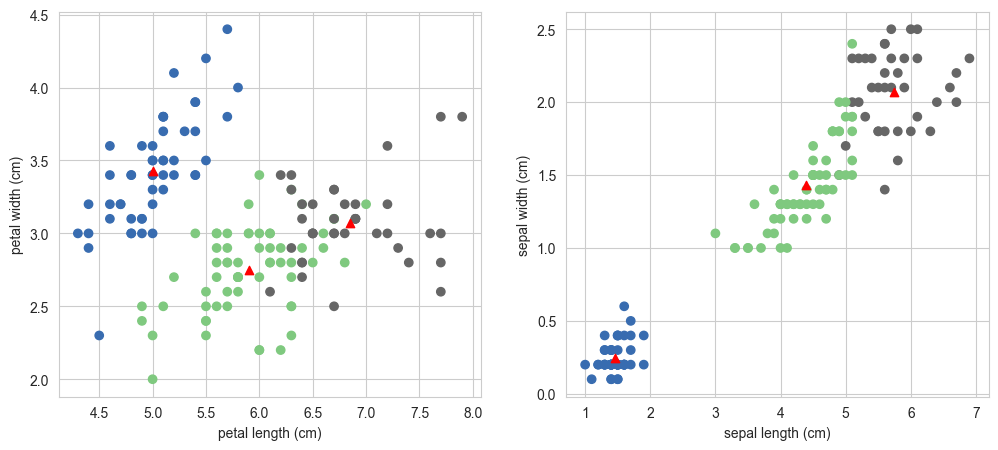

In [24]:

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.scatter(X[:,0],X[:,1],c = pred, cmap=cm.Accent)
plt.grid(True)
for center in kmeans.cluster_centers_:
    center = center[:2]
    plt.scatter(center[0],center[1],marker = '^',c = 'red')
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
     
plt.subplot(1,2,2)   
plt.scatter(X[:,2],X[:,3],c = pred, cmap=cm.Accent)
plt.grid(True)
for center in kmeans.cluster_centers_:
    center = center[2:4]
    plt.scatter(center[0],center[1],marker = '^',c = 'red')
plt.xlabel("sepal length (cm)")
plt.ylabel("sepal width (cm)")
plt.show()

1- The subplot on the left display petal length vs. petal width with data points colored by clusters, and red markers indicate K-means cluster centers. 

2- The subplot on the right show sepal length vs. sepal width similarly.

# Summary

1- K-means is a partitioning method that divides a dataset into ‘k’ distinct, non-overlapping subsets (clusters) based on similarity, aiming to minimize the variance within each cluster.

2- K-means clustering is a powerful unsupervised machine learning algorithm for grouping unlabeled datasets.  

3- Its objective is to divide data into clusters, making similar data points part of the same group.

4- The algorithm initializes cluster centroids and iteratively assigns data points to the nearest centroid, updating centroids based on the mean of points in each cluster.

5- Customer segmentation in marketing, where k-means groups customers based on purchasing behavior, allowing businesses to tailor marketing strategies for different segments.

6- K-means works well with numerical data, where the concept of distance between data points is meaningful. It’s commonly applied to continuous variables.

7- K-means is primarily used for clustering and grouping similar data points. It does not predict labels for new data; it assigns them to existing clusters based on similarity.

8- The objective is to partition data into ‘k’ clusters, minimizing the intra-cluster variance. It seeks to form groups where data points within each cluster are more similar to each other than to those in other clusters.

# Hierarchical clustering

1- Hierarchical clustering is a connectivity-based clustering model that groups the data points together that are close to each other based on the measure of similarity or distance. 

2- The assumption is that data points that are close to each other are more similar or related than data points that are farther apart.

3- A dendrogram, a tree-like figure produced by hierarchical clustering, depicts the hierarchical relationships between groups. 

4- Individual data points are located at the bottom of the dendrogram, while the largest clusters, which include all the data points, are located at the top. In order to generate different numbers of clusters, the dendrogram can be sliced at various heights.

5- The dendrogram is created by iteratively merging or splitting clusters based on a measure of similarity or distance between data points. 

6- Clusters are divided or merged repeatedly until all data points are contained within a single cluster, or until the predetermined number of clusters is attained.

7- We can look at the dendrogram and measure the height at which the branches of the dendrogram form distinct clusters to calculate the ideal number of clusters. T

8- he dendrogram can be sliced at this height to determine the number of clusters.

9- Types of Hierarchical Clustering Basically, there are two types of hierarchical Clustering:

    Agglomerative Clustering

    Divisive clustering

# Hierarchical Agglomerative Clustering

1- It is also known as the bottom-up approach or hierarchical agglomerative clustering (HAC). 

2- A structure that is more informative than the unstructured set of clusters returned by flat clustering. 

3- This clustering algorithm does not require us to prespecify the number of clusters. 

4- Bottom-up algorithms treat each data as a singleton cluster at the outset and then successively agglomerate pairs of clusters until all clusters have been merged into a single cluster that contains all data. 

![alt text](Untitled-Diagram71.png)

In [26]:
from sklearn.cluster import AgglomerativeClustering 
import numpy as np 
  
# randomly chosen dataset 
X = np.array([[1, 2], [1, 4], [1, 0], 
              [4, 2], [4, 4], [4, 0]]) 
  
# here we need to mention the number of clusters 
# otherwise the result will be a single cluster 
# containing all the data 
clustering = AgglomerativeClustering(n_clusters=2).fit(X) 
  
# print the class labels 
print(clustering.labels_) 

[1 1 1 0 0 0]


# Hierarchical Divisive clustering

1- It is also known as a top-down approach. 

2- This algorithm also does not require to prespecify the number of clusters.

3-  Top-down clustering requires a method for splitting a cluster that contains the whole data and proceeds by splitting clusters recursively until individual data have been split into singleton clusters.

![alt text](Untitled-Diagram-153-1.png)

# Computing Distance Matrix

1- While merging two clusters we check the distance between two every pair of clusters and merge the pair with the least distance/most similarity. 

2- But the question is how is that distance determined. There are different ways of defining Inter Cluster distance/similarity. Some of them are:

    a- Min Distance: Find the minimum distance between any two points of the cluster.

    b- Max Distance: Find the maximum distance between any two points of the cluster.

    c- Group Average: Find the average distance between every two points of the clusters.

    d- Ward’s Method: The similarity of two clusters is based on the increase in squared error when two clusters are merged.

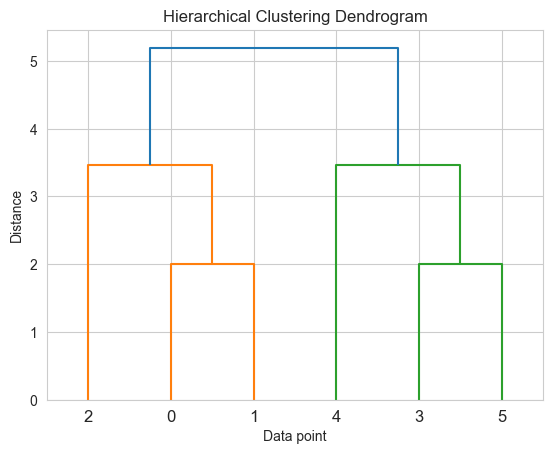

In [25]:
import numpy as np 
from scipy.cluster.hierarchy import dendrogram, linkage 
import matplotlib.pyplot as plt 
  
# randomly chosen dataset 
X = np.array([[1, 2], [1, 4], [1, 0], 
              [4, 2], [4, 4], [4, 0]]) 
  
# Perform hierarchical clustering 
Z = linkage(X, 'ward') 
  
# Plot dendrogram 
dendrogram(Z) 
  
plt.title('Hierarchical Clustering Dendrogram') 
plt.xlabel('Data point') 
plt.ylabel('Distance') 
plt.show()